# Milestone 4 · Notebook 3: Training, Tuning and Evaluation

**Project:** Deepfake Voice Detection for Indian Languages · Group-3

This notebook brings the whole of Milestone 4 together: the data and its preprocessing, the two baseline models, the tuned
final XLS-R model (with augmentation), and how they compare across runs, epochs and test sets.

**What runs here and what is loaded.** The training runs themselves (about 60 GPU-hours) were done one at a time with
`02_training.ipynb` across four Kaggle accounts. This notebook loads their logs and checkpoints, and re-runs everything
that is cheap: preprocessing on sample clips, the shape check, scoring the test sets with the saved checkpoints, and
every metric and figure.

| Input | Where it comes from |
| --- | --- |
| Code, configs, and each run's logs and `run.json` | This repository, branch `milestone-4` (`src/`, `configs/`, `results/`) |
| Preprocessed audio and manifest | Kaggle dataset `dsai-group3-m4-data` |
| Model checkpoints (`best.pt` per run) | The outputs of the team's training notebooks, attached as inputs |

**Runtime:** about 1 hour on a Kaggle T4 with `RESCORE = True`; a few minutes with `RESCORE = False`.

**Test data:** this notebook scores a fixed Milestone-4 sample of each test set (`m4_eval`, 500 real + 500 fake
per split). The full test sets (~124k clips) are scored in Milestone 5.

| Section | Contents |
| --- | --- |
| 1 | Data and preprocessing |
| 2 | Before and after preprocessing |
| 3 | Baseline training (LFCC-LCNN, AASIST-L) |
| 4 | Final model: XLS-R tuning, augmentation and training |
| 5 | Baseline models vs final model |
| 6 | Comparison across runs and epochs |
| 7 | Metrics of the final model |
| 8 | Training artifacts |
| 9 | Summary and key findings |

## Setup

In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"  # keep the notebook output readable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import Audio, display
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve

SEED = 42
RESCORE = False         # True: score again with the saved checkpoints (~30 min per XLS-R model). False: load
                        # the predictions src/score.py saved for each run (results/<run>/predictions.csv).
DEFAULT_RUN = "T-01"    # XLS-R with the default config, tuning subset (baseline of the Table A sweeps)
DEFAULT_FIXED_RUN = "T-01c"  # the same, on the data without the start click (baseline of the Table B runs)
DEFAULT_FULL_RUN = "D-01"    # the default config on the full train split (compared with the final model)
FINAL_RUNS = ["F-01", "F-02", "F-03"]                       # final config with seeds 42, 43, 44
BASELINE_RUNS = {"LFCC-LCNN": "A-01", "AASIST-L": "A-02"}   # the two baseline models (Milestone 1)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
LABELS = ["real", "fake"]
TEST_SPLITS = ["test_indomain", "test_unseen_gen", "test_phone", "test_itw", "test_asvspoof"]

The code comes from the repository (cloned on Kaggle). The data and checkpoints are found wherever Kaggle mounts them
under `/kaggle/input`.

In [2]:
URL = "https://github.com/thehimanshhu/Group-3-DS-and-AI-Lab-Project"
REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir()), None)
if REPO is None:
    subprocess.run(["git", "clone", "-q", "--depth", "1", "-b", "milestone-4", URL, "repo"], check=True)
    REPO = Path("repo").resolve()
sys.path.insert(0, str(REPO))
RESULTS = REPO / "results"
COMMIT = subprocess.run(["git", "-C", str(REPO), "rev-parse", "--short", "HEAD"],
                        capture_output=True, text=True).stdout.strip()


def find(pattern, fallback):
    found = sorted(Path("/kaggle/input").glob(pattern))
    return found[0] if found else fallback


MANIFEST = find("**/manifests/manifest_m4.csv", REPO / "data" / "m4" / "manifests" / "manifest_m4.csv")
DATA = MANIFEST.parents[1]
manifest = pd.read_csv(MANIFEST, keep_default_na=False)
from src.collect_runs import collect

runs = collect(RESULTS)   # one row per results/<run_id>/run.json
print(f"Code at commit {COMMIT} | {len(manifest):,} clips | {len(runs)} training runs logged | device: {DEVICE}")

Code at commit 6ab0c9e | 37,796 clips | 35 training runs logged | device: cuda


Small helpers used throughout: the run files and the EER.

In [3]:
def checkpoint(run_id):
    return find(f"**/{run_id}/best.pt", REPO / "checkpoints" / run_id / "best.pt")


def config(run_id):
    return yaml.safe_load(open(RESULTS / run_id / "config.yaml"))


def step_log(run_id):    # one row per training step: epoch, step, loss, lr
    return pd.read_csv(RESULTS / run_id / "train_log.csv")


def epoch_log(run_id):   # one row per epoch: epoch, train_loss, valid_loss, valid_eer, minutes
    return pd.read_csv(RESULTS / run_id / "epoch_log.csv")


def eer(is_fake, scores):
    """Equal error rate, and the threshold where it's reached."""
    fpr, tpr, thresholds = roc_curve(is_fake, scores)
    i = np.nanargmin(np.abs((1 - tpr) - fpr))
    return (fpr[i] + 1 - tpr[i]) / 2, thresholds[i]

## 1. Data and Preprocessing

### 1.1 The data

What each split is for. The split is by speaker (70 / 15 / 15, seed 42), so no speaker is in two splits; the leakage
checks are in `01_data_preparation.ipynb`.

| Split | Contents | Used for |
| --- | --- | --- |
| `train` | Kathbath (real) + IndicSynth (fake) in Hindi, Tamil, Telugu; ASVspoof 2019 LA train (English) | Training |
| `valid` | The same sources, with other speakers; ASVspoof dev | Early stopping, choosing settings, the threshold |
| `test_indomain` | The same sources, with the test speakers | New speakers, known generators |
| `test_unseen_gen` | Kathbath test speakers + our Indic Parler-TTS, IndicF5 and MMS-TTS clips | Generators never seen in training |
| `test_phone` | `test_indomain` through a simulated phone channel | Phone-call audio |
| `test_itw` | In-the-Wild (English) | Real-world audio |
| `test_asvspoof` | ASVspoof 2019 LA eval, attacks A07–A19 | English attacks never seen in training |

In [4]:
manifest.pivot_table(index="split", columns="label", values="clip_id", aggfunc="count",
                     margins=True, margins_name="total").loc[["train", "valid", *[s for s in TEST_SPLITS
                     if s in set(manifest.split)], "total"]]

label,fake,real,total
split,,,
train,14468,14485,28953
valid,1978,1974,3952
test_indomain,500,500,1000
test_unseen_gen,500,500,1000
test_phone,500,500,1000
test_itw,477,465,942
test_asvspoof,473,476,949
total,18896,18900,37796


In [5]:
manifest.pivot_table(index=["split"], columns=["language"], values="clip_id", aggfunc="count", fill_value=0)

language,en,hi,ta,te
split,,,,
test_asvspoof,949,0,0,0
test_indomain,0,334,333,333
test_itw,942,0,0,0
test_phone,0,334,333,333
test_unseen_gen,0,331,335,334
train,4957,7999,7998,7999
valid,952,1000,1000,1000


### 1.2 Preprocessing

Every clip, real or fake, goes through the same steps (`src/preprocess.py`), so that sample rate, format, edge silence
and loudness can't give the label away.

| # | Step | Setting |
| --- | --- | --- |
| 1 | Decode, mix to mono | `soundfile`; m4a through `ffmpeg` |
| 2 | Resample | 16 kHz |
| 3 | Trim edge silence | 20 ms frames more than 40 dB below the loudest frame |
| 4 | Drop very short clips | Less than 1 s left |
| 5 | Normalise loudness | RMS −20 dBFS, peak at most 0.99 |
| 6 | Store and hash | 16-bit PCM WAV, SHA-1 |

At load time (`src/dataset.py`), each clip is then cropped or zero-padded to the training length, scaled to zero mean
and unit variance, and given an attention mask.

**Check:** preprocessing a few original clips again here gives exactly the stored files. (The original files are
kept for only a few clips per source, to save space.)

In [6]:
from src.preprocess import preprocess
import soundfile as sf

with_raw = manifest[manifest.raw_path != ""]   # a few original files are kept per source
check = with_raw.groupby("dataset").sample(1, random_state=SEED)
for row in check.itertuples():
    again = preprocess(open(DATA / row.raw_path, "rb").read())
    stored, _ = sf.read(DATA / row.path, dtype="float32")
    same = again is not None and len(again) == len(stored) and np.abs(again - stored).max() < 1e-4
    print(f"{row.dataset:12s} {row.clip_id:40s} identical: {same}")

asvspoof2019_la asvspoof_LA_T_1138215                    identical: True
generated    ta_0382_indic-parler-tts                 identical: True
in_the_wild  itw_4483                                 identical: True
indicsynth   indicsynth_ta_freevc24____f____src_1099____tgt_781___30 identical: True
kathbath     kathbath_ta_844424932781679-203-f        identical: True


In [7]:
pd.read_csv(DATA / "manifests" / "dropped.csv").groupby(["dataset", "reason"]).size().rename("clips dropped")

dataset          reason                              
asvspoof2019_la  shorter than 1 s after the start cut     88
                 shorter than 1 s after trimming         214
in_the_wild      shorter than 1 s after the start cut      8
                 shorter than 1 s after trimming          50
indicsynth       shorter than 1 s after trimming           4
Name: clips dropped, dtype: int64

In [8]:
manifest.groupby("dataset").orig_sr.value_counts().unstack(fill_value=0).rename(columns=lambda sr: f"{sr / 1000:g} kHz")

orig_sr,16 kHz,24 kHz,44.1 kHz
dataset,,,
asvspoof2019_la,6858,0,0
generated,168,168,164
in_the_wild,942,0,0
indicsynth,500,13996,0
kathbath,14500,0,500


After preprocessing every clip is 16 kHz.

## 2. Before and After Preprocessing

One real clip (Kathbath, Hindi) and one fake clip (IndicSynth FreeVC24, Hindi), as stored in the source (`raw_path`)
and after preprocessing (`path`).

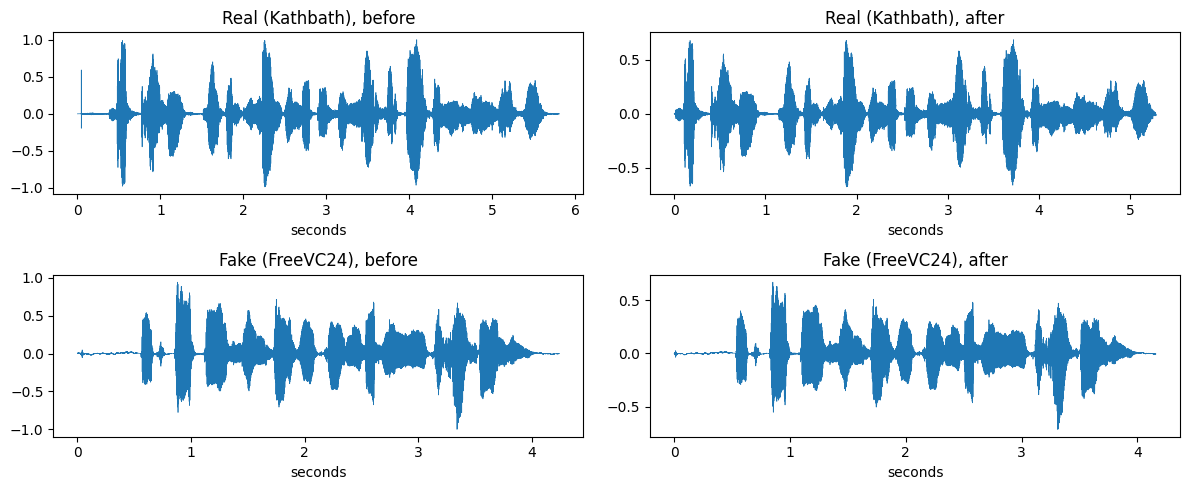

,clip,stage,sample rate,duration (s),RMS (dBFS),peak
0,Real (Kathbath),before,16000,5.80,-17.1,1.000
1,Real (Kathbath),after,16000,5.28,-20.0,0.686
2,Fake (FreeVC24),before,24000,4.24,-17.1,1.000
3,Fake (FreeVC24),after,16000,4.16,-20.0,0.713


In [9]:
from src.preprocess import decode

examples = {
    "Real (Kathbath)": manifest[(manifest.dataset == "kathbath") & (manifest.language == "hi")
                                & (manifest.raw_path != "")].iloc[0],
    "Fake (FreeVC24)": manifest[(manifest.generator == "freevc24") & (manifest.language == "hi")
                               & (manifest.raw_path != "")].iloc[0],
}

fig, axes = plt.subplots(len(examples), 2, figsize=(12, 5), squeeze=False)
stats = []
for r, (name, row) in enumerate(examples.items()):
    raw, raw_sr = decode(open(DATA / row.raw_path, "rb").read())
    proc, proc_sr = sf.read(DATA / row.path, dtype="float32")
    for c, (stage, wave, sr) in enumerate([("before", raw, raw_sr), ("after", proc, proc_sr)]):
        axes[r, c].plot(np.arange(len(wave)) / sr, wave, linewidth=0.5)
        axes[r, c].set_title(f"{name}, {stage}")
        axes[r, c].set_xlabel("seconds")
        stats.append({"clip": name, "stage": stage, "sample rate": sr, "duration (s)": round(len(wave) / sr, 2),
                      "RMS (dBFS)": round(20 * np.log10(np.sqrt(np.mean(wave ** 2)) + 1e-12), 1),
                      "peak": round(float(np.abs(wave).max()), 3)})
plt.tight_layout()
plt.show()
pd.DataFrame(stats)

/usr/local/lib/python3.13/dist-packages/matplotlib/axes/_axes.py:8233: RuntimeWarning: divide by zero encountered in log10
  Z = 10. * np.log10(spec)


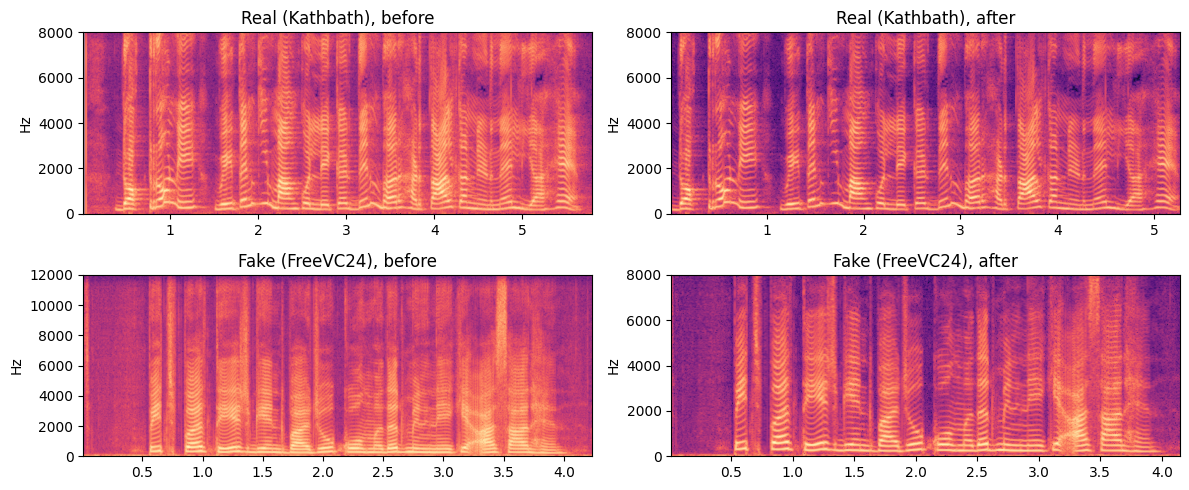

Real (Kathbath)


Fake (FreeVC24)


In [10]:
fig, axes = plt.subplots(len(examples), 2, figsize=(12, 5), squeeze=False)
for r, (name, row) in enumerate(examples.items()):
    raw, raw_sr = decode(open(DATA / row.raw_path, "rb").read())
    proc, proc_sr = sf.read(DATA / row.path, dtype="float32")
    for c, (stage, wave, sr) in enumerate([("before", raw, raw_sr), ("after", proc, proc_sr)]):
        axes[r, c].specgram(wave, Fs=sr, NFFT=512, noverlap=384, cmap="magma")
        axes[r, c].set_title(f"{name}, {stage}")
        axes[r, c].set_ylabel("Hz")
plt.tight_layout()
plt.show()
for name, row in examples.items():
    print(name)
    display(Audio(DATA / row.path))

**What changed:** _filled in after the run (sample rate, silence, loudness)._

### 2.1 Check for a shortcut at the start of clips

In Milestone 3 we found a peak about 47 ms into real Kathbath clips (about 7 ms after trimming), which a model could
use instead of the voice. The mean loudness envelope of the first 200 ms, real vs fake, in `train`:

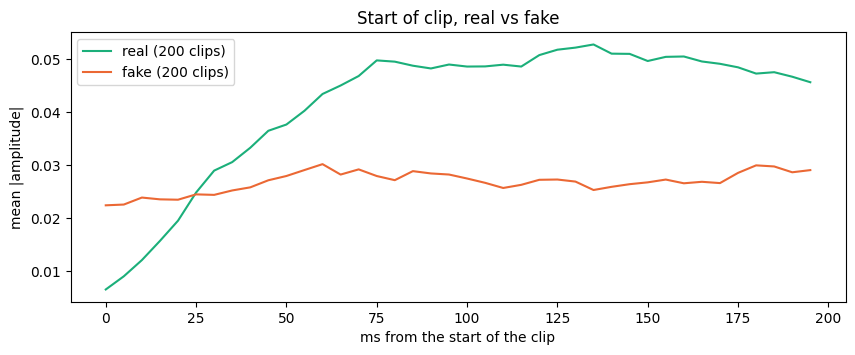

In [11]:
win = int(0.005 * 16000)   # 5 ms
fig, ax = plt.subplots(figsize=(10, 3.5))
for label, color in [("real", "#1baf7a"), ("fake", "#eb6834")]:
    rows = manifest[(manifest.split == "train") & (manifest.label == label)
                    & (manifest.language != "en")].sample(200, random_state=SEED)
    env = np.mean([np.abs(sf.read(DATA / p, dtype="float32", frames=3200)[0]).reshape(-1, win).mean(1)
                   for p in rows.path], axis=0)
    ax.plot(np.arange(len(env)) * 5, env, color=color, label=f"{label} (200 clips)")
ax.set(xlabel="ms from the start of the clip", ylabel="mean |amplitude|", title="Start of clip, real vs fake")
ax.legend()
plt.show()

_If real and fake still differ here, the random time offset in augmentation (Section 4.4) removes the cue._

## 3. Baseline Training

The two baseline models chosen in Milestone 1, trained **from scratch** on the same data, splits and preprocessing as
XLS-R. They show what XLS-R's multilingual pretraining adds (Section 5).

| Model | Input | Architecture | Parameters | Why it's a baseline |
| --- | --- | --- | --- | --- |
| LFCC-LCNN (Lavrentyeva et al., 2019) | LFCC features, 20 ms frames | Light CNN with max-feature-map activations | Small | The standard spectrogram CNN of ASVspoof 2019 |
| AASIST-L (Jung et al., 2022) | Raw waveform | Sinc filters + spectro-temporal graph attention | ~85K | A strong, light end-to-end detector |

### 3.1 Baseline training configurations

In [12]:
pd.DataFrame({name: pd.json_normalize(config(run_id)).iloc[0] for name, run_id in BASELINE_RUNS.items()}).fillna("—")

,LFCC-LCNN,AASIST-L
run_id,A-01,A-02
seed,42,42
experiment.owner,Amit,Amit
experiment.param,model.name,model.name
experiment.value,lfcc_lcnn,aasist_l
data.manifest,manifests/manifest_m4.csv,manifests/manifest_m4.csv
data.sample_rate,16000,16000
data.crop_seconds,4.0,4.0
data.tune_subset,False,False
model.name,lfcc_lcnn,aasist_l


### 3.2 Baseline training curves

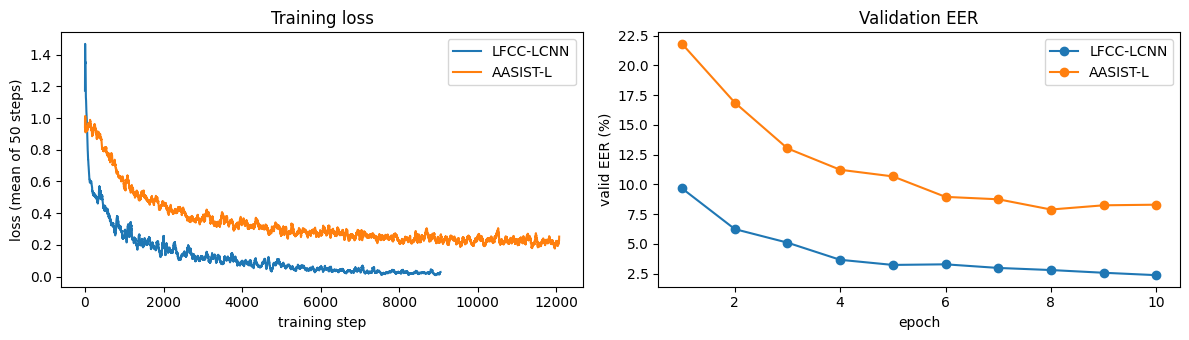

,run_id,epochs,best_valid_eer,train_minutes
0,A-01,10,0.02379,21.3
1,A-02,10,0.07895,145.9


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for name, run_id in BASELINE_RUNS.items():
    log, ep = step_log(run_id), epoch_log(run_id)
    axes[0].plot(log.step, log.loss.rolling(50, min_periods=1).mean(), label=name)
    axes[1].plot(ep.epoch, ep.valid_eer * 100, marker="o", label=name)
axes[0].set(xlabel="training step", ylabel="loss (mean of 50 steps)", title="Training loss")
axes[1].set(xlabel="epoch", ylabel="valid EER (%)", title="Validation EER")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()
runs[runs.run_id.isin(BASELINE_RUNS.values())][["run_id", "epochs", "best_valid_eer", "train_minutes"]]

**Observations:** _filled in after the runs._

## 4. Final Model: XLS-R Tuning, Augmentation and Training

XLS-R starts from a **default config**. Each experiment changes **one** setting of it and is judged on `valid` EER
only. The test splits are scored only for the final models (Section 5).

### 4.1 The model

| Step | Output shape |
| --- | --- |
| Input: a clip cropped or zero-padded to 4 s, zero mean, unit variance, with an attention mask | `[B, 64000]` |
| XLS-R CNN feature encoder (pretrained, frozen): one frame every 20 ms | `[B, 199, 512]` |
| XLS-R transformer, 24 layers (pretrained, fine-tuned) | `[B, 199, 1024]` |
| Mean pooling over frames that hold audio | `[B, 1024]` |
| Dropout → Linear(1024, 2) | `[B, 2]` |
| Softmax → `p_fake` → verdict at the threshold from `valid` | `[B]` |

**Softmax vs sigmoid:** for two classes, softmax over two logits equals sigmoid of their difference, so the results are
the same. We use two logits because `CrossEntropyLoss` takes one weight per class directly, and the head can later grow
to more classes.

**Attention mask:** short clips are zero-padded to 4 s, and the mask tells the transformer and the mean pooling to
ignore the padded frames. So the amount of padding can't change the score or give the label away.

In [14]:
from src.dataset import ClipDataset
from src.model import build_model
from torch.utils.data import DataLoader

default_cfg = config(DEFAULT_RUN)
model = build_model(default_cfg["model"]).to(DEVICE)
total = sum(p.numel() for p in model.parameters())
trained = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Parameters: {total / 1e6:.1f} M, of which {trained / 1e6:.1f} M are trained")

loader = DataLoader(ClipDataset(manifest[manifest.split == "train"], DATA, default_cfg["data"], train=True),
                    batch_size=default_cfg["train"]["batch_size"], shuffle=True,
                    generator=torch.Generator().manual_seed(SEED))
wave, mask, label, _ = next(iter(loader))
model.eval()
with torch.no_grad():
    logits = model(wave.to(DEVICE), mask.to(DEVICE))
print("input", tuple(wave.shape), "| mask", tuple(mask.shape), "| logits", tuple(logits.shape))

Parameters: 315.4 M, of which 311.2 M are trained
input (8, 64000) | mask (8, 64000) | logits (8, 2)


### 4.2 The default configuration

The complete settings of the default run, read from its saved `config.yaml`.

In [15]:
pd.json_normalize(default_cfg).T.rename(columns={0: "value"})

,value
run_id,T-01
seed,42
experiment.owner,Tarika
experiment.param,None
experiment.value,None
data.manifest,manifests/manifest_m4.csv
data.sample_rate,16000
data.crop_seconds,4.0
data.tune_subset,True
model.name,facebook/wav2vec2-xls-r-300m


| Setting | Why |
| --- | --- |
| Weighted cross-entropy | Class weights from `train` only, so an imbalance can't bias the model |
| AdamW, 1e-5 for XLS-R, 1e-3 for the head | XLS-R keeps its pretrained knowledge; the new head learns faster |
| Warmup + cosine schedule | Avoids large early updates that can wreck the pretrained weights |
| Early stopping on `valid` EER | Stops before overfitting; the best epoch is kept |
| fp16, gradient clipping | Fits a T4's memory; keeps training stable |

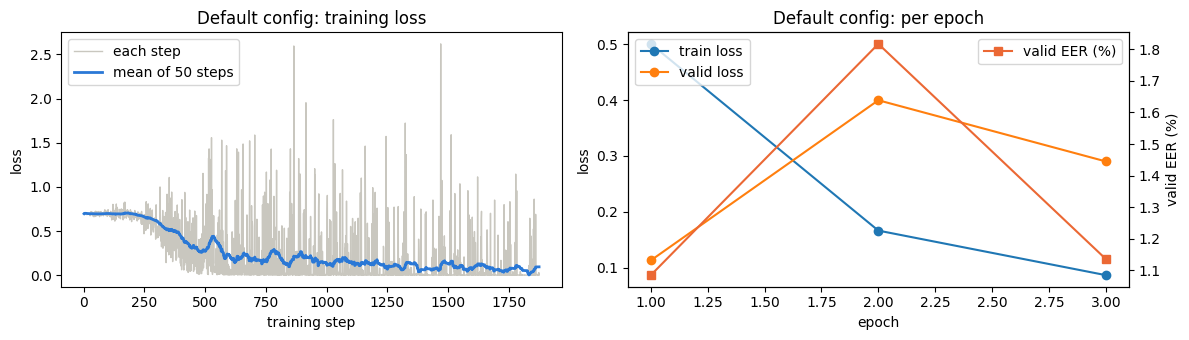

,epoch,train_loss,valid_loss,train_eer,valid_eer,minutes
0,1,0.50055,0.11319,0.02198,0.01085,7.97
1,2,0.16652,0.39974,0.01800,0.01817,7.04
2,3,0.08679,0.29026,0.02000,0.01136,7.04


In [16]:
log, ep = step_log(DEFAULT_RUN), epoch_log(DEFAULT_RUN)
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.5))
a.plot(log.step, log.loss, color="#c9c7bf", linewidth=1, label="each step")
a.plot(log.step, log.loss.rolling(50, min_periods=1).mean(), color="#2a78d6", linewidth=2, label="mean of 50 steps")
a.set(xlabel="training step", ylabel="loss", title="Default config: training loss")
a.legend()
b.plot(ep.epoch, ep.train_loss, marker="o", label="train loss")
b.plot(ep.epoch, ep.valid_loss, marker="o", label="valid loss")
b2 = b.twinx()
b2.plot(ep.epoch, ep.valid_eer * 100, marker="s", color="#eb6834", label="valid EER (%)")
b.set(xlabel="epoch", ylabel="loss", title="Default config: per epoch")
b2.set_ylabel("valid EER (%)")
b.legend(loc="upper left")
b2.legend(loc="upper right")
plt.tight_layout()
plt.show()
ep

### 4.3 Hyperparameter experiments

Each hyperparameter is swept over several values, changing only that one from the default config. So that several
values could be tried, the sweeps ran on a fixed **tuning subset** (5,000 `train` clips, 3 epochs) and were scored on
the full `valid`. For every value: the best `valid` EER, and the EER on 1,000 training clips (no augmentation) at the
same epoch. A large gap between the two means overfitting; both high means underfitting. Choices are made on `valid`
only, never on a test split.

In [17]:
final_cfg = config(FINAL_RUNS[0])
default_flat, final_flat = pd.json_normalize(default_cfg).iloc[0], pd.json_normalize(final_cfg).iloc[0]
sweeps = runs[runs.run_id.str.match(r"[TV]-\d+") & runs.param.notna()]
params = [p for p in sweeps.param.unique() if p in default_flat.index]


def sweep(param):
    """Every run of one sweep, plus the default run, sorted by value."""
    runs_of_param = sweeps[sweeps.param == param]
    # Table B (V) runs used the click-free data, so their baseline is T-01c; Table A (T) runs compare with T-01
    base = DEFAULT_FIXED_RUN if runs_of_param.run_id.str.startswith("V").all() else DEFAULT_RUN
    part = pd.concat([runs_of_param, runs[runs.run_id == base].assign(param=param, value=default_flat[param])])
    numeric = pd.to_numeric(part.value, errors="coerce")
    if numeric.notna().all():
        return part.assign(value=numeric).sort_values("value"), True
    return part.assign(value=part.value.astype(str)), False


sweeps[["run_id", "param", "value", "epochs", "train_eer", "best_valid_eer", "train_minutes"]].sort_values(["param", "run_id"])

,run_id,param,value,epochs,train_eer,best_valid_eer,train_minutes
29,V-06,augment,noise + gain,3,0.01100,0.01518,22.3
30,V-07,augment,speed + pitch + reverb,3,0.02600,0.04580,21.8
31,V-08,augment,rawboost,3,0.00700,0.01468,21.8
32,V-09,augment,codec / phone,3,0.00400,0.00607,25.3
33,V-10,augment,all,3,0.15799,0.20698,31.9
16,T-07,data.crop_seconds,2.0,3,0.02900,0.01969,18.8
17,T-08,data.crop_seconds,6.0,3,0.00400,0.00757,25.3
24,V-01,model.dropout,0.0,3,0.00200,0.01265,22.7
25,V-02,model.dropout,0.3,3,0.01000,0.01012,21.2
26,V-03,model.dropout,0.5,3,0.00500,0.00734,21.3


**Training vs validation EER for each hyperparameter.** The dashed line marks the value in the final config.

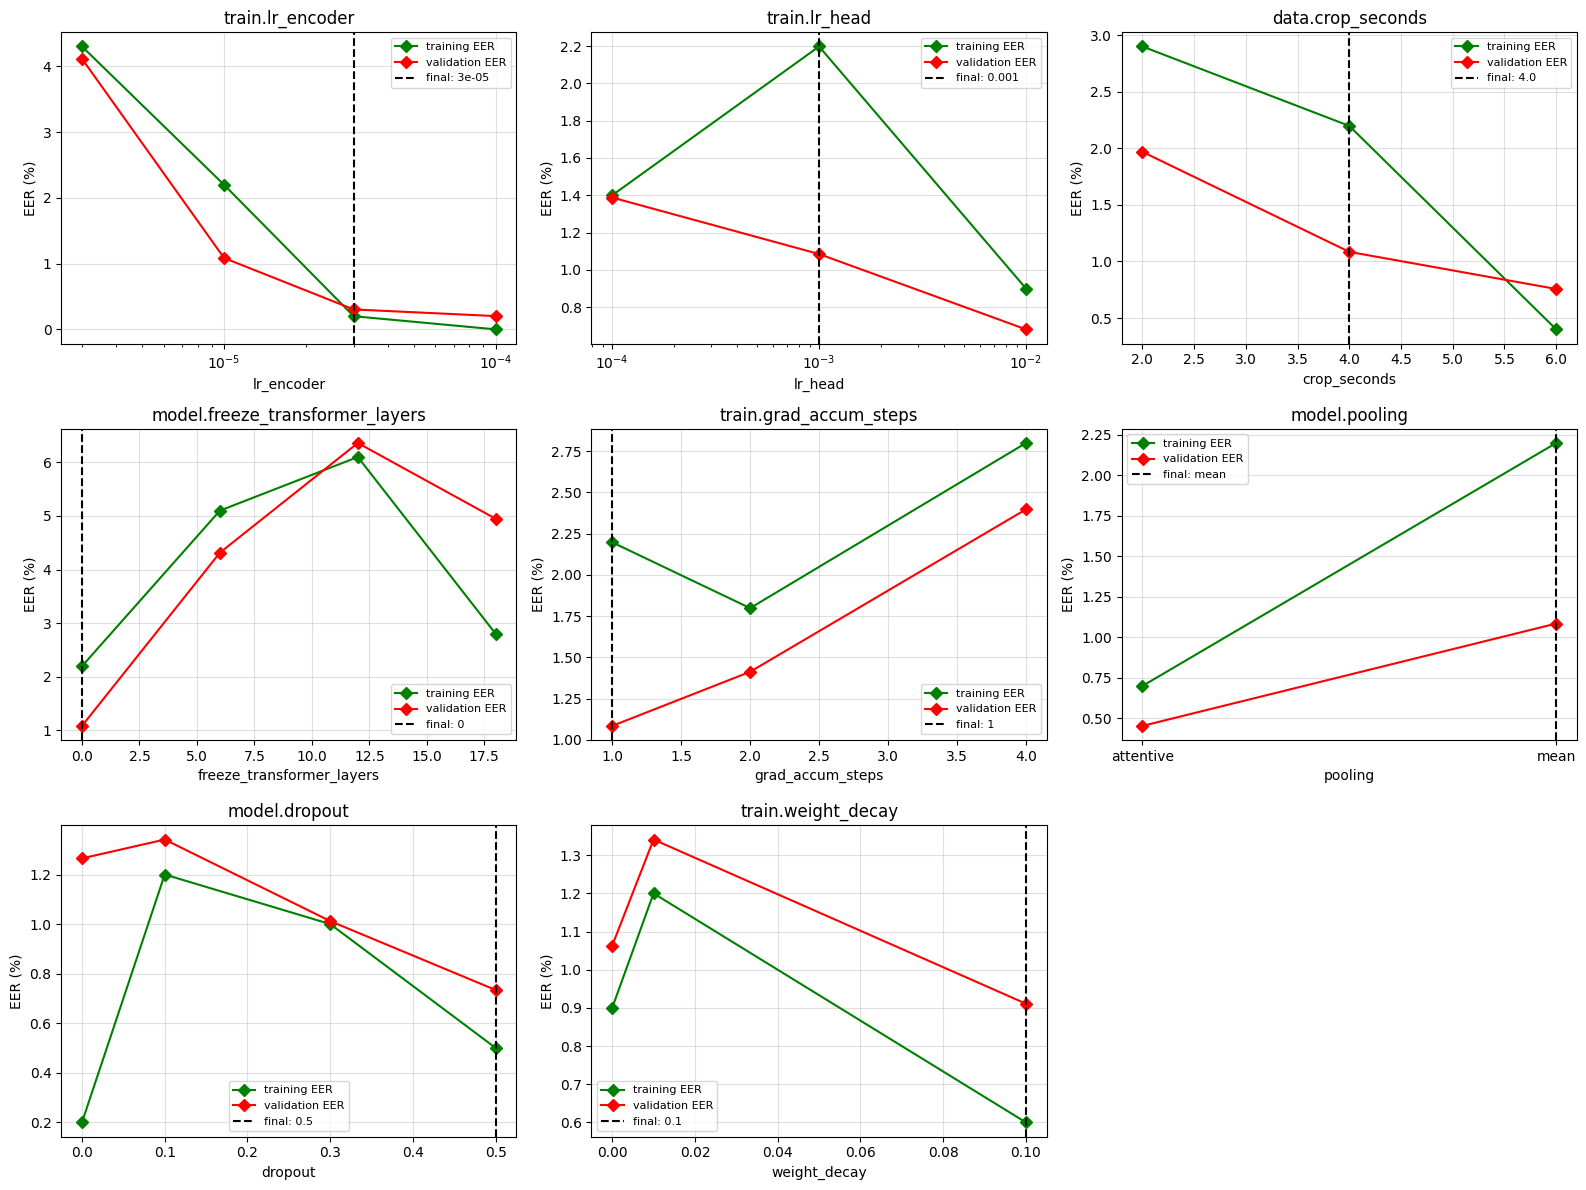

In [18]:
cols = 3
fig, axes = plt.subplots(int(np.ceil(len(params) / cols)), cols, figsize=(16, 4 * int(np.ceil(len(params) / cols))),
                         squeeze=False)
for ax, param in zip(axes.flat, params):
    part, numeric = sweep(param)
    x = part.value if numeric else np.arange(len(part))
    ax.plot(x, part.train_eer * 100, "D-", color="green", label="training EER")
    ax.plot(x, part.best_valid_eer * 100, "D-", color="red", label="validation EER")
    chosen = final_flat[param]
    if numeric:
        ax.axvline(float(chosen), color="black", linestyle="--", label=f"final: {chosen}")
        if part.value.min() > 0 and part.value.max() / part.value.min() >= 10:
            ax.set_xscale("log")
    else:
        ax.set_xticks(x, part.value)
        if str(chosen) in list(part.value):
            ax.axvline(list(part.value).index(str(chosen)), color="black", linestyle="--", label=f"final: {chosen}")
    ax.set(title=param, xlabel=param.split(".")[-1], ylabel="EER (%)")
    ax.grid(True, alpha=0.4)
    ax.legend(fontsize=8)
for ax in axes.flat[len(params):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**The values tried, the best on `valid`, and what went into the final config:**

In [19]:
rows = []
for param in params:
    part, _ = sweep(param)
    best = part.loc[part.best_valid_eer.idxmin()]
    rows.append({"hyperparameter": param, "values tried": ", ".join(map(str, part.value)),
                 "default": default_flat[param], "best on valid": best.value,
                 "best valid EER (%)": round(best.best_valid_eer * 100, 1), "final config": final_flat[param]})
pd.DataFrame(rows).set_index("hyperparameter")

,values tried,default,best on valid,best valid EER (%),final config
hyperparameter,,,,,
train.lr_encoder,"3e-06, 1e-05, 3e-05, 0.0001",0.00001,0.0001,0.2,0.00003
train.lr_head,"0.0001, 0.001, 0.01",0.001,0.01,0.7,0.001
data.crop_seconds,"2.0, 4.0, 6.0",4.0,6.0,0.8,4.0
model.freeze_transformer_layers,"0, 6, 12, 18",0,0,1.1,0
train.grad_accum_steps,"1, 2, 4",1,1,1.1,1
model.pooling,"attentive, mean",mean,attentive,0.5,mean
model.dropout,"0.0, 0.1, 0.3, 0.5",0.1,0.5,0.7,0.5
train.weight_decay,"0.0, 0.01, 0.1",0.01,0.1,0.9,0.1


**Why each final value:**

| Hyperparameter | Final value | Why |
| --- | --- | --- |
| Encoder learning rate | _after the runs_ | |
| Head learning rate | | |
| Crop length | | |
| Frozen transformer layers | | |
| Batch size | | |
| Pooling | | |
| Dropout | | |
| Weight decay | | |

Where two values are within the seed-to-seed spread (Section 6.4), the cheaper or simpler one is chosen.

### 4.4 Augmentation

Augmentation is applied only to training clips, each with its own probability (`src/augment.py`). One clip under
each augmentation:

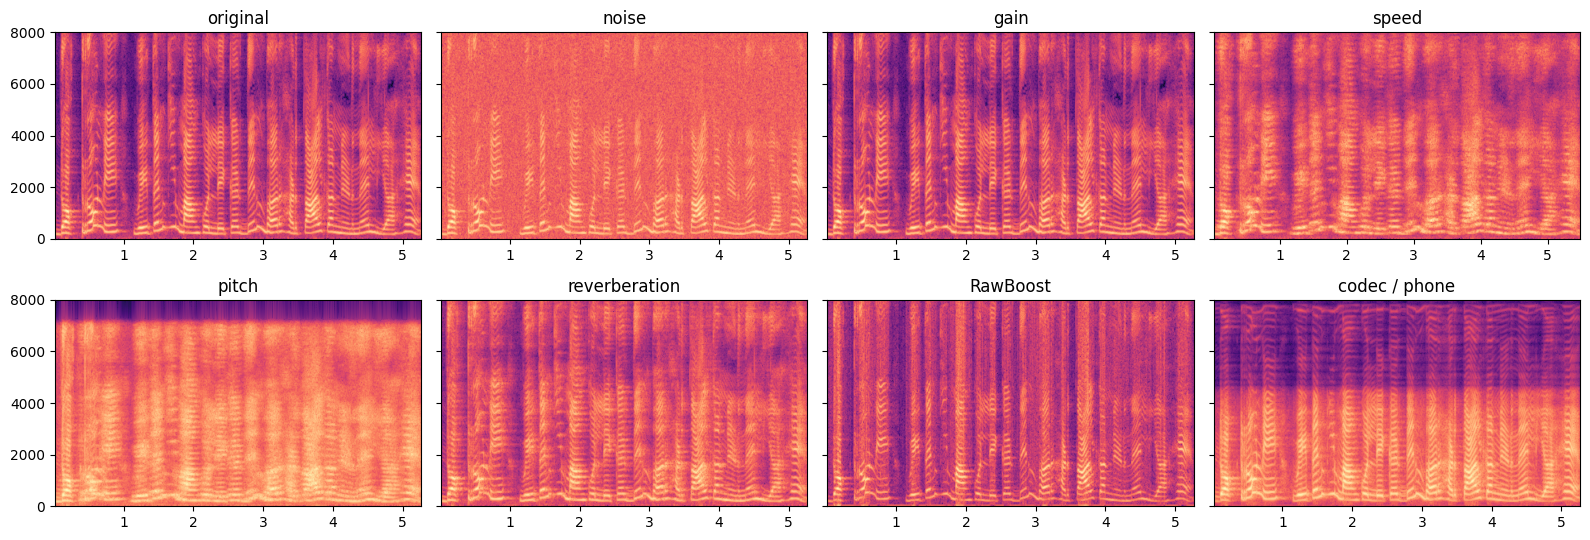

original


noise


gain


speed


pitch


reverberation


RawBoost


codec / phone


In [20]:
import shutil

from src import augment

FFMPEG = shutil.which("ffmpeg") or __import__("imageio_ffmpeg").get_ffmpeg_exe()

clip = examples["Real (Kathbath)"]
wave, sr = sf.read(DATA / clip.path, dtype="float32")
rng = np.random.default_rng(SEED)
versions = {"original": wave, "noise": augment.add_noise(wave, rng), "gain": augment.random_gain(wave, rng),
            "speed": augment.speed(wave, sr, rng), "pitch": augment.pitch(wave, sr, rng),
            "reverberation": augment.reverb(wave, sr, rng), "RawBoost": augment.rawboost(wave, rng),
            "codec / phone": augment.codec(wave, sr, rng, ffmpeg_path=FFMPEG)}

fig, axes = plt.subplots(2, len(versions) // 2, figsize=(16, 5.5), sharey=True)
for ax, (name, w) in zip(axes.flat, versions.items()):
    ax.specgram(w, Fs=sr, NFFT=512, noverlap=384, cmap="magma")
    ax.set_title(name)
plt.tight_layout()
plt.show()
for name, w in versions.items():
    print(name)
    display(Audio(w, rate=sr))

### 4.5 Regularization and training stability

In [21]:
reg = runs[runs.run_id.str.match(r"V-\d+") | (runs.run_id == DEFAULT_FIXED_RUN)].sort_values("run_id")
reg = reg.assign(setting_changed=reg["param"].fillna("default"))
reg["setting_changed"] += reg["value"].map(lambda v: "" if pd.isna(v) else f" = {v}")
reg[["run_id", "setting_changed", "epochs", "best_valid_eer", "train_minutes"]]

,run_id,setting_changed,epochs,best_valid_eer,train_minutes
10,T-01c,default,3,0.01341,21.3
24,V-01,model.dropout = 0.0,3,0.01265,22.7
25,V-02,model.dropout = 0.3,3,0.01012,21.2
26,V-03,model.dropout = 0.5,3,0.00734,21.3
27,V-04,train.weight_decay = 0.0,3,0.01063,21.1
28,V-05,train.weight_decay = 0.1,3,0.00911,21.4
29,V-06,augment = noise + gain,3,0.01518,22.3
30,V-07,augment = speed + pitch + reverb,3,0.04580,21.8
31,V-08,augment = rawboost,3,0.01468,21.8
32,V-09,augment = codec / phone,3,0.00607,25.3


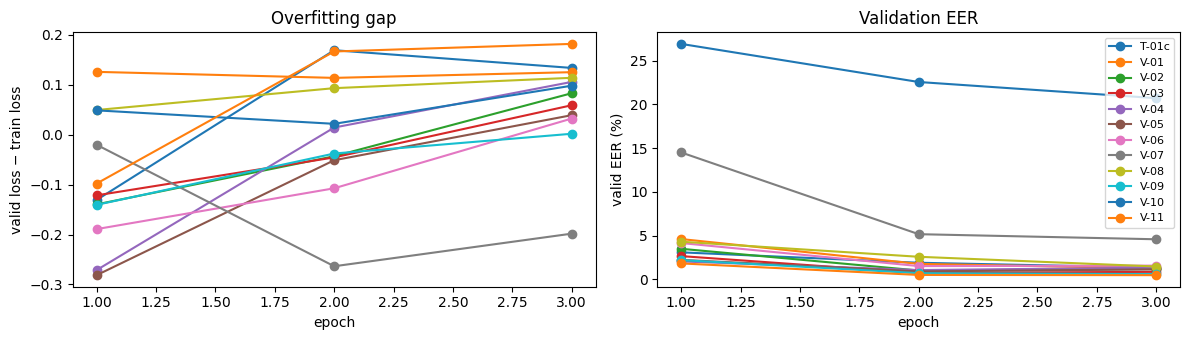

In [22]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.5))
for run_id in reg.run_id:
    ep = epoch_log(run_id)
    a.plot(ep.epoch, ep.valid_loss - ep.train_loss, marker="o", label=run_id)
    b.plot(ep.epoch, ep.valid_eer * 100, marker="o", label=run_id)
a.set(xlabel="epoch", ylabel="valid loss − train loss", title="Overfitting gap")
b.set(xlabel="epoch", ylabel="valid EER (%)", title="Validation EER")
b.legend(fontsize=8)
plt.tight_layout()
plt.show()

| Technique | Aim | Effect on `valid` EER |
| --- | --- | --- |
| Noise and gain augmentation | Generalization | _after the runs_ |
| Speed, pitch, reverberation | Generalization to new voices and rooms | |
| RawBoost | Generalization to unseen generators | |
| Codec / phone-channel augmentation | Phone-call audio | |
| Dropout 0.3 | Less overfitting | |
| Weight decay | Less overfitting | |
| Warmup + gradient clipping | Training stability | |
| Early stopping | Keeps the best epoch | |

### 4.6 The final configuration and its training

The best settings from 4.3–4.5 combined, trained with three seeds. The table shows only what differs from the default.

In [23]:
final_cfg = config(FINAL_RUNS[0])
flat_default, flat_final = pd.json_normalize(default_cfg).iloc[0], pd.json_normalize(final_cfg).iloc[0]
changed = [k for k in flat_final.index if k in flat_default.index and flat_default[k] != flat_final[k] and k != "run_id"]
pd.DataFrame({"default": flat_default[changed], "final": flat_final[changed]})

,default,final
experiment.owner,Tarika,Himanshu
experiment.value,None,final config
data.tune_subset,True,False
model.dropout,0.1,0.5
train.epochs,3,8
train.lr_encoder,0.00001,0.00003
train.weight_decay,0.01,0.1
augment.channel.enabled,False,True


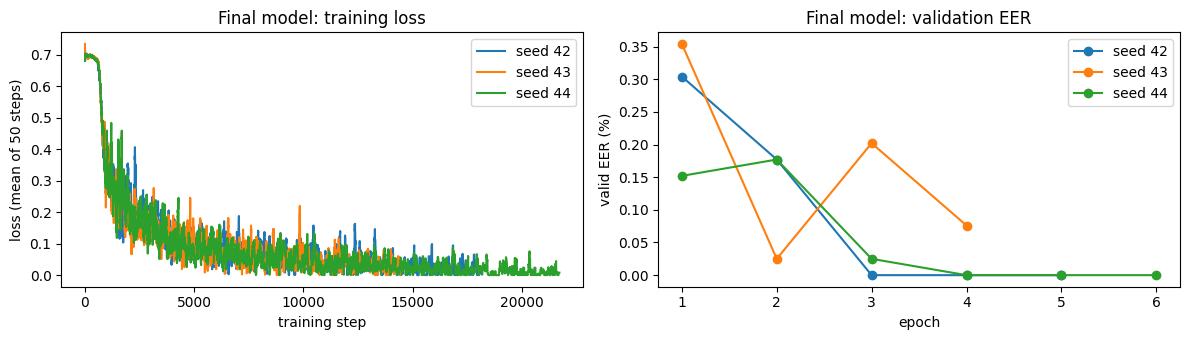

,run_id,epochs,best_valid_eer,train_minutes
6,F-01,5,0.00000,267.2
7,F-02,4,0.00025,182.1
8,F-03,6,0.00000,249.3


In [24]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.5))
for run_id in FINAL_RUNS:
    log, ep = step_log(run_id), epoch_log(run_id)
    seed = config(run_id)["seed"]
    a.plot(log.step, log.loss.rolling(50, min_periods=1).mean(), label=f"seed {seed}")
    b.plot(ep.epoch, ep.valid_eer * 100, marker="o", label=f"seed {seed}")
a.set(xlabel="training step", ylabel="loss (mean of 50 steps)", title="Final model: training loss")
b.set(xlabel="epoch", ylabel="valid EER (%)", title="Final model: validation EER")
a.legend()
b.legend()
plt.tight_layout()
plt.show()
runs[runs.run_id.isin(FINAL_RUNS)][["run_id", "epochs", "best_valid_eer", "train_minutes"]]

## 5. Baseline Models vs Final Model

All of `valid` and the Milestone-4 test sample (`m4_eval`: 500 real + 500 fake per test split) are scored by the two baselines, XLS-R with the default config, and the final XLS-R (seed
42). Each clip is scored over **several 4 s windows** (every 2 s), and `p_fake` is their mean; `p_fake_middle` keeps
the Milestone-3 score of the middle 4 s only. With `RESCORE = False`, the predictions saved by each run are loaded
instead. The full test sets (~124k clips) are scored in Milestone 5.

In [25]:
from src.evaluate import score
from src.model import load_model

eval_rows = manifest[(manifest.split == "valid") | (manifest.m4_eval == True)]
models = {**BASELINE_RUNS, "XLS-R default": DEFAULT_FULL_RUN, "XLS-R final": FINAL_RUNS[0]}
preds = {}
for name, run_id in models.items():
    if RESCORE:
        preds[name] = score(load_model(checkpoint(run_id), config(run_id), DEVICE), eval_rows, DATA,
                            config(run_id)["data"], DEVICE)
    else:
        preds[name] = pd.read_csv(RESULTS / run_id / "predictions.csv", keep_default_na=False)
{name: len(p) for name, p in preds.items()}

{'LFCC-LCNN': 8843,
 'AASIST-L': 8843,
 'XLS-R default': 8843,
 'XLS-R final': 8843}

In [26]:
def eer_table(pred):
    out = {}
    for split in TEST_SPLITS:
        part = pred[pred.split == split]
        if len(part):
            out[split] = eer(part.label == "fake", part.p_fake)[0] * 100
    return pd.Series(out)


comparison = pd.DataFrame({name: eer_table(p) for name, p in preds.items()}).round(1)
comparison["final − best baseline"] = comparison["XLS-R final"] - comparison[list(BASELINE_RUNS)].min(axis=1)
comparison.rename_axis("EER (%)")

,LFCC-LCNN,AASIST-L,XLS-R default,XLS-R final,final − best baseline
EER (%),,,,,
test_indomain,1.3,6.8,0.0,0.0,-1.3
test_unseen_gen,28.9,20.8,6.5,6.5,-14.3
test_phone,43.2,13.7,0.3,0.0,-13.7
test_itw,83.2,19.3,10.6,7.4,-11.9
test_asvspoof,29.0,27.7,10.4,5.2,-22.5


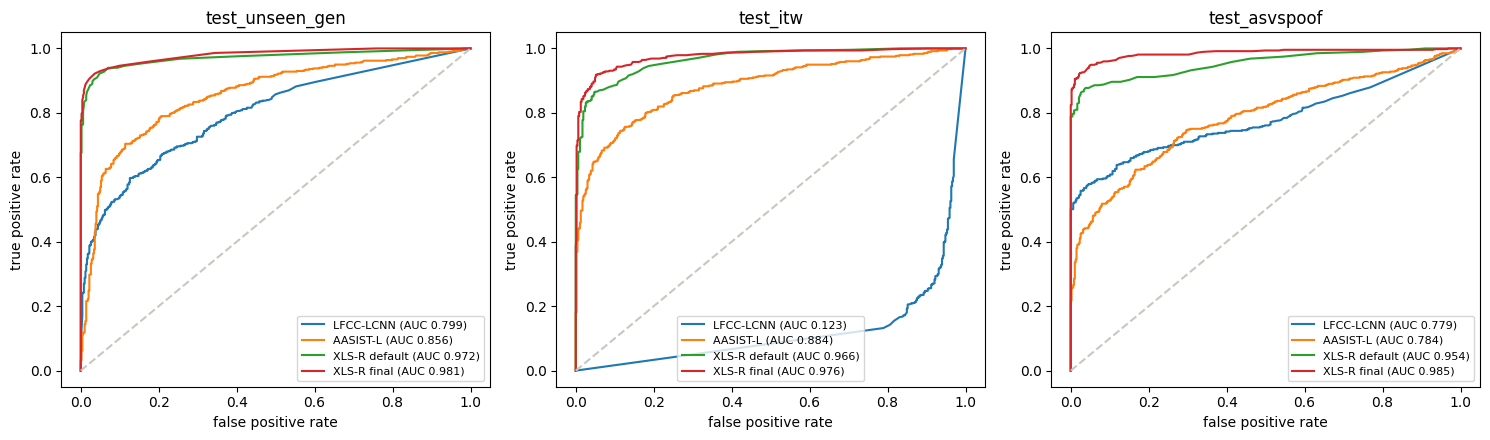

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, split in zip(axes, ["test_unseen_gen", "test_itw", "test_asvspoof"]):
    for name, p in preds.items():
        part = p[p.split == split]
        fpr, tpr, _ = roc_curve(part.label == "fake", part.p_fake)
        ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(part.label == 'fake', part.p_fake):.3f})")
    ax.plot([0, 1], [0, 1], color="#c9c7bf", linestyle="--")
    ax.set(title=split, xlabel="false positive rate", ylabel="true positive rate")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**What XLS-R adds over the baselines, and what tuning adds over the default:** _filled in after the run._

## 6. Comparison Across Runs and Epochs

### 6.1 The final model across epochs

After each epoch, run F-01 scored the 1,000 training clips, all of `valid`, and a fixed 300 clips of every test split.
The epoch is chosen on `valid` alone; the test curves are only observed.

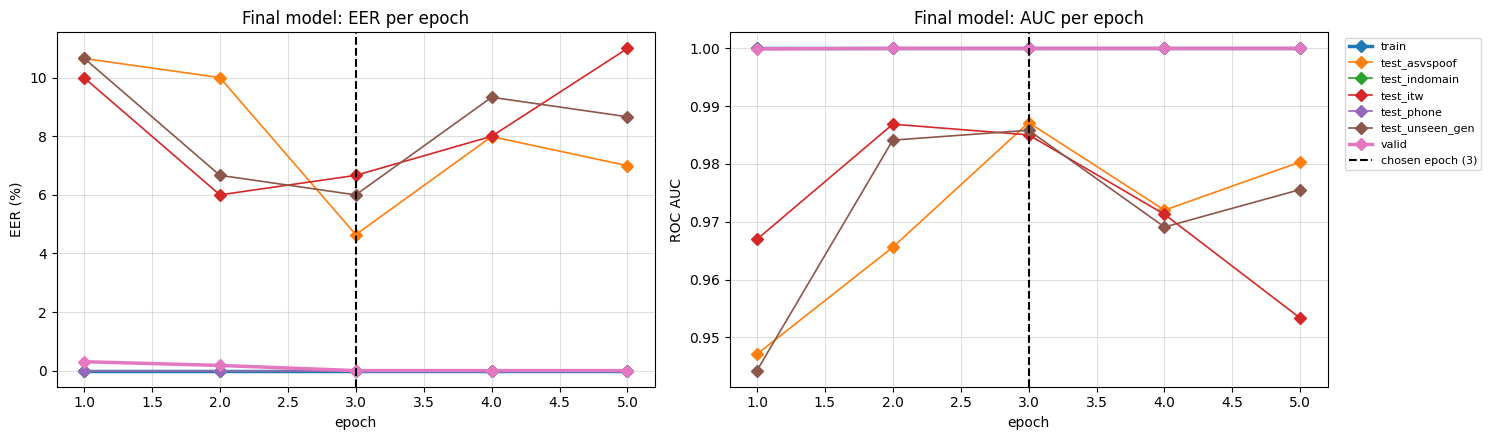

split,test_asvspoof,test_indomain,test_itw,test_phone,test_unseen_gen,train,valid
epoch,,,,,,,
1,10.7,0.0,10.0,0.0,10.7,0.0,0.3
2,10.0,0.0,6.0,0.0,6.7,0.0,0.2
3,4.6,0.0,6.7,0.0,6.0,0.0,0.0
4,8.0,0.0,8.0,0.0,9.3,0.0,0.0
5,7.0,0.0,11.0,0.0,8.7,0.0,0.0


In [28]:
ev = pd.read_csv(RESULTS / FINAL_RUNS[0] / "epoch_eval.csv")   # epoch, split, eer, auc, accuracy
best_epoch = epoch_log(FINAL_RUNS[0]).set_index("epoch").valid_eer.idxmin()
fig, (a, b) = plt.subplots(1, 2, figsize=(15, 4.5))
for split, part in ev.groupby("split", sort=False):
    width = 2.5 if split in ("train", "valid") else 1.2
    a.plot(part.epoch, part.eer * 100, marker="D", linewidth=width, label=split)
    b.plot(part.epoch, part.auc, marker="D", linewidth=width, label=split)
for ax in (a, b):
    ax.axvline(best_epoch, color="black", linestyle="--", label=f"chosen epoch ({best_epoch})")
    ax.set_xlabel("epoch")
    ax.grid(True, alpha=0.4)
a.set(ylabel="EER (%)", title="Final model: EER per epoch")
b.set(ylabel="ROC AUC", title="Final model: AUC per epoch")
b.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()
(ev.pivot(index="epoch", columns="split", values="eer") * 100).round(1)

**What the epochs show:** _filled in after the run (where training and validation part, and whether the test splits follow `valid`)._

### 6.2 Validation EER per epoch, every run

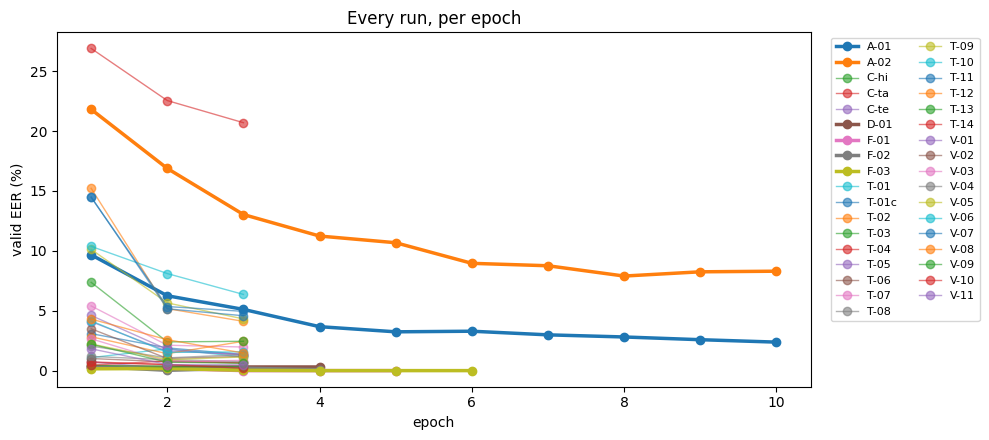

In [29]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for run_id in runs.run_id:
    if (RESULTS / run_id / "epoch_log.csv").exists():
        ep = epoch_log(run_id)
        style = dict(linewidth=2.5) if run_id in FINAL_RUNS + [DEFAULT_FULL_RUN, *BASELINE_RUNS.values()] else dict(linewidth=1, alpha=0.6)
        ax.plot(ep.epoch, ep.valid_eer * 100, marker="o", label=run_id, **style)
ax.set(xlabel="epoch", ylabel="valid EER (%)", title="Every run, per epoch")
ax.legend(ncol=2, fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 6.3 Best epoch and early stopping

In [30]:
rows = []
for run_id in runs.run_id:
    if (RESULTS / run_id / "epoch_log.csv").exists():
        ep = epoch_log(run_id)
        best = ep.loc[ep.valid_eer.idxmin()]
        rows.append({"run": run_id, "epochs run": len(ep), "best epoch": int(best.epoch),
                     "best valid EER (%)": round(best.valid_eer * 100, 1),
                     "stopped early": len(ep) < config(run_id)["train"]["epochs"],
                     "minutes": round(ep.minutes.sum(), 1)})
pd.DataFrame(rows).sort_values("best valid EER (%)")

,run,epochs run,best epoch,best valid EER (%),stopped early,minutes
6,F-01,5,3,0.0,True,267.2
7,F-02,4,2,0.0,True,182.1
8,F-03,6,4,0.0,True,249.3
4,C-te,3,3,0.1,False,76.3
13,T-04,3,3,0.2,False,21.5
5,D-01,4,2,0.3,True,137.5
2,C-hi,3,1,0.3,False,78.1
3,C-ta,3,3,0.3,False,77.1
12,T-03,3,2,0.3,False,21.5
23,T-14,3,1,0.5,False,21.9


### 6.4 Variation between seeds

The final config trained three times with different seeds. Differences between experiments smaller than this spread
can't be told apart from chance.

In [31]:
seed_eers = pd.DataFrame({run_id: pd.Series(json.load(open(RESULTS / run_id / "results.json"))["eer"])
                          for run_id in FINAL_RUNS}) * 100
seed_eers.assign(mean=seed_eers.mean(axis=1), std=seed_eers.std(axis=1)).round(1).rename_axis("EER (%)")

,F-01,F-02,F-03,mean,std
EER (%),,,,,
valid,0.0,0.2,0.0,0.1,0.1
test_indomain,0.0,0.0,0.0,0.0,0.0
test_unseen_gen,6.5,9.2,9.8,8.5,1.8
test_phone,0.0,0.0,0.0,0.0,0.0
test_itw,7.4,9.2,8.7,8.5,0.9
test_asvspoof,5.2,16.0,9.1,10.1,5.5


## 7. Metrics of the Final Model

| Metric | What it measures |
| --- | --- |
| **EER** (main metric) | The error rate where fakes accepted as real equal real clips rejected as fake; doesn't depend on a threshold |
| **ROC AUC** | How well the scores rank fakes above real clips |
| **Accuracy, confusion matrix** | Results at the decision threshold, chosen at the EER point of `valid` |
| **Share of fakes caught** | Per generator and language, at the threshold |

### 7.1 Results per test split

In [32]:
final = preds["XLS-R final"].copy()
valid = final[final.split == "valid"]
_, THRESHOLD = eer(valid.label == "fake", valid.p_fake)
final["predicted"] = np.where(final.p_fake >= THRESHOLD, "fake", "real")
print(f"Decision threshold (EER point of valid): p_fake >= {THRESHOLD:.3f}")

rows = []
for split in ["valid", *TEST_SPLITS]:
    part = final[final.split == split]
    if len(part):
        is_fake = part.label == "fake"
        rows.append({"split": split, "clips": len(part), "EER (%)": round(eer(is_fake, part.p_fake)[0] * 100, 1),
                     "ROC AUC": round(roc_auc_score(is_fake, part.p_fake), 3),
                     "accuracy": round((part.predicted == part.label).mean(), 3)})
results = pd.DataFrame(rows).set_index("split")
results

Decision threshold (EER point of valid): p_fake >= 0.994


,clips,EER (%),ROC AUC,accuracy
split,,,,
valid,3952,0.0,1.000,1.000
test_indomain,1000,0.0,1.000,1.000
test_unseen_gen,1000,6.5,0.981,0.675
test_phone,1000,0.0,1.000,0.998
test_itw,942,7.4,0.976,0.880
test_asvspoof,949,5.2,0.985,0.902


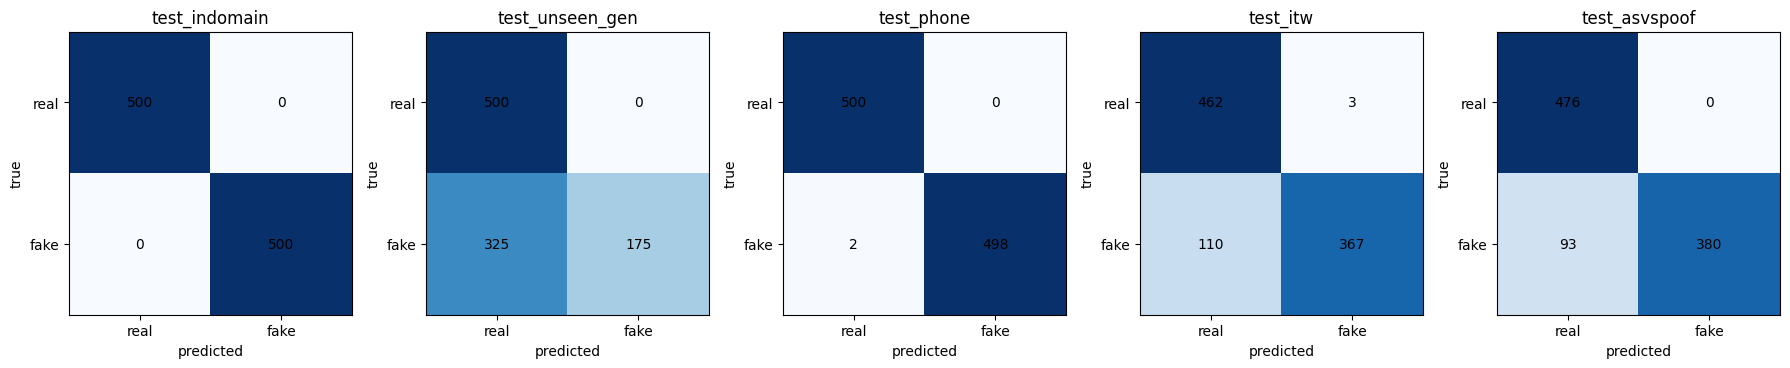

In [33]:
fig, axes = plt.subplots(1, len(TEST_SPLITS), figsize=(18, 3.5))
for ax, split in zip(axes, TEST_SPLITS):
    part = final[final.split == split]
    cm = confusion_matrix(part.label, part.predicted, labels=LABELS)
    ax.imshow(cm, cmap="Blues")
    for (i, j), n in np.ndenumerate(cm):
        ax.text(j, i, n, ha="center", va="center")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=LABELS, yticklabels=LABELS, title=split,
           xlabel="predicted", ylabel="true")
plt.tight_layout()
plt.show()

### 7.2 Comparison across splits

Every model on every test split: EER (lower is better) and ROC AUC (higher is better).

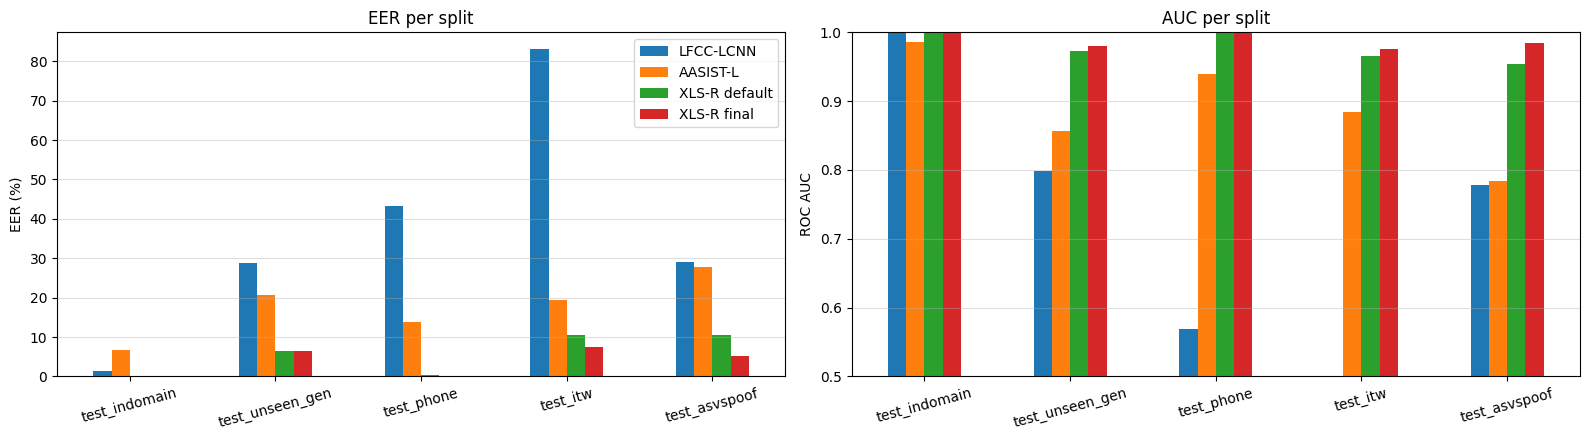

,LFCC-LCNN,AASIST-L,XLS-R default,XLS-R final
ROC AUC,,,,
test_indomain,0.999,0.986,1.000,1.000
test_unseen_gen,0.799,0.856,0.972,0.981
test_phone,0.569,0.939,1.000,1.000
test_itw,0.123,0.884,0.966,0.976
test_asvspoof,0.779,0.784,0.954,0.985


In [34]:
auc_table = pd.DataFrame({name: {split: roc_auc_score(part.label == "fake", part.p_fake)
                                 for split in TEST_SPLITS if len(part := p[p.split == split])}
                          for name, p in preds.items()})
fig, (a, b) = plt.subplots(1, 2, figsize=(16, 4.5))
comparison[list(preds)].plot.bar(ax=a, rot=15)
auc_table.plot.bar(ax=b, rot=15, legend=False)
a.set(ylabel="EER (%)", title="EER per split")
b.set(ylabel="ROC AUC", title="AUC per split", ylim=(0.5, 1))
for ax in (a, b):
    ax.grid(True, axis="y", alpha=0.4)
plt.tight_layout()
plt.show()
auc_table.round(3).rename_axis("ROC AUC")

### 7.3 Comparison across languages

EER of the final model per test split and language (English only appears in `test_itw` and `test_asvspoof`), then
every model per language over all its test clips.

/tmp/ipykernel_51/1145997968.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_lang = tests.groupby(["split", "language"]).apply(eer_or_nan).unstack().reindex(TEST_SPLITS).round(1)


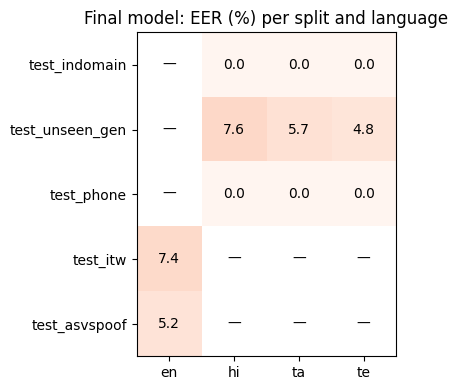

In [35]:
def eer_or_nan(part):
    return eer(part.label == "fake", part.p_fake)[0] * 100 if part.label.nunique() == 2 else np.nan


tests = final[final.split.isin(TEST_SPLITS)]
by_lang = tests.groupby(["split", "language"]).apply(eer_or_nan).unstack().reindex(TEST_SPLITS).round(1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.imshow(by_lang.values, cmap="Reds", vmin=0, vmax=50)
for (i, j), v in np.ndenumerate(by_lang.values):
    ax.text(j, i, "—" if np.isnan(v) else f"{v:.1f}", ha="center", va="center")
ax.set(xticks=range(len(by_lang.columns)), xticklabels=by_lang.columns, yticks=range(len(by_lang.index)),
       yticklabels=by_lang.index, title="Final model: EER (%) per split and language")
plt.tight_layout()
plt.show()

In [36]:
pd.DataFrame({name: p[p.split.isin(TEST_SPLITS)].groupby("language").apply(eer_or_nan)
              for name, p in preds.items()}).round(1).rename_axis("EER (%), all test splits")

/tmp/ipykernel_51/85790310.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pd.DataFrame({name: p[p.split.isin(TEST_SPLITS)].groupby("language").apply(eer_or_nan)
/tmp/ipykernel_51/85790310.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pd.DataFrame({name: p[p.split.isin(TEST_SPLITS)].groupby("language").apply(eer_or_nan)
/tmp/ipykernel_51/85790310.py:1: FutureWarning: DataFrameGroupBy.apply operated on the g

,LFCC-LCNN,AASIST-L,XLS-R default,XLS-R final
"EER (%), all test splits",,,,
en,50.0,23.7,11.3,6.4
hi,31.0,16.2,2.8,2.9
ta,33.0,11.5,3.1,3.0
te,33.7,16.2,3.4,3.1


### 7.4 Unseen generators: share of fakes caught, per language

In [37]:
unseen_fakes = final[(final.split == "test_unseen_gen") & (final.label == "fake")]
unseen_fakes.assign(caught=unseen_fakes.predicted == "fake").pivot_table(
    index="generator", columns="language", values="caught", aggfunc="mean", margins=True, margins_name="all").round(3)

language,hi,ta,te,all
generator,,,,
indic-parler-tts,0.566,0.536,0.291,0.463
indicf5,0.107,0.232,0.179,0.173
mms-tts,0.821,0.321,0.107,0.417
all,0.497,0.363,0.192,0.350


### 7.5 ASVspoof eval: share of fakes caught, per attack

Training now uses every ASVspoof train attack (A01–A06); eval has attacks A07–A19, none seen in training.

In [38]:
asv_fakes = final[(final.split == "test_asvspoof") & (final.label == "fake")]
asv_fakes.assign(caught=asv_fakes.predicted == "fake").groupby("generator").caught.agg(["mean", "size"]).round(3)

,mean,size
generator,,
A07,0.780,41
A08,0.971,35
A09,1.000,36
A10,0.057,35
A11,0.250,36
A12,0.730,37
A13,0.971,35
A14,1.000,38
A15,0.784,37


### 7.6 One 4 s window vs several windows

In [39]:
pd.DataFrame({split: {"middle 4 s (M3)": eer(part.label == "fake", part.p_fake_middle)[0] * 100,
                      "mean of windows": eer(part.label == "fake", part.p_fake)[0] * 100}
              for split in TEST_SPLITS if len(part := final[final.split == split])}).T.round(1).rename_axis("EER (%)")

,middle 4 s (M3),mean of windows
EER (%),,
test_indomain,0.0,0.0
test_unseen_gen,6.1,6.5
test_phone,0.0,0.0
test_itw,7.5,7.4
test_asvspoof,5.2,5.2


### 7.7 Cross-language test

Trained on two Indian languages, tested on the third (runs `C-hi`, `C-ta`, `C-te`).

In [40]:
cross = {run_id: json.load(open(RESULTS / run_id / "results.json")) for run_id in ["C-hi", "C-ta", "C-te"]
         if (RESULTS / run_id / "results.json").exists()}
pd.DataFrame({run_id: {"held-out language": r["held_out_language"], "EER on it (%)": round(r["eer_held_out"] * 100, 1)}
              for run_id, r in cross.items()}).T

,held-out language,EER on it (%)
C-hi,hi,3.5
C-ta,ta,2.7
C-te,te,3.9


### 7.8 One threshold for every source?

In Milestone 3 the `valid` threshold called every ASVspoof eval clip fake. Here: accuracy at the `valid` threshold,
each split's own EER threshold, and the score distributions.

In [41]:
rows = []
for split in TEST_SPLITS:
    part = final[final.split == split]
    if len(part):
        own_eer, own_t = eer(part.label == "fake", part.p_fake)
        rows.append({"split": split, "accuracy at the valid threshold": round((part.predicted == part.label).mean(), 3),
                     "this split's own EER threshold": round(own_t, 3)})
pd.DataFrame(rows).set_index("split")

,accuracy at the valid threshold,this split's own EER threshold
split,,
test_indomain,1.000,0.996
test_unseen_gen,0.675,0.000
test_phone,0.998,0.834
test_itw,0.880,0.001
test_asvspoof,0.902,0.001


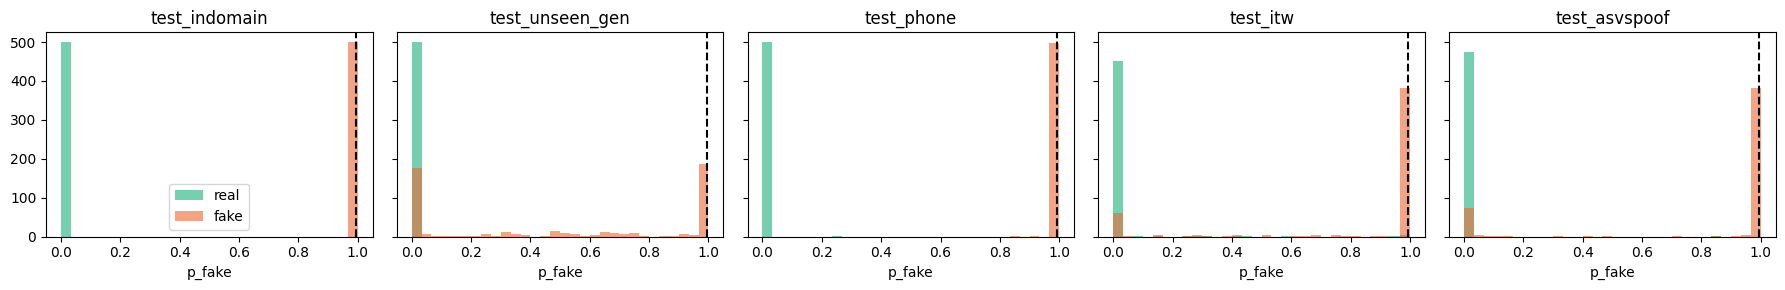

In [42]:
fig, axes = plt.subplots(1, len(TEST_SPLITS), figsize=(18, 3), sharey=True)
for ax, split in zip(axes, TEST_SPLITS):
    part = final[final.split == split]
    for label, color in [("real", "#1baf7a"), ("fake", "#eb6834")]:
        ax.hist(part[part.label == label].p_fake, bins=30, range=(0, 1), alpha=0.6, color=color, label=label)
    ax.axvline(THRESHOLD, color="black", linestyle="--")
    ax.set(title=split, xlabel="p_fake")
axes[0].legend()
plt.tight_layout()
plt.show()

### 7.9 Explanation view

Which parts of the clip drive the verdict: the gradient of `p_fake` with respect to the input, smoothed over time
(`src/explain.py`), for one caught fake and one real clip.

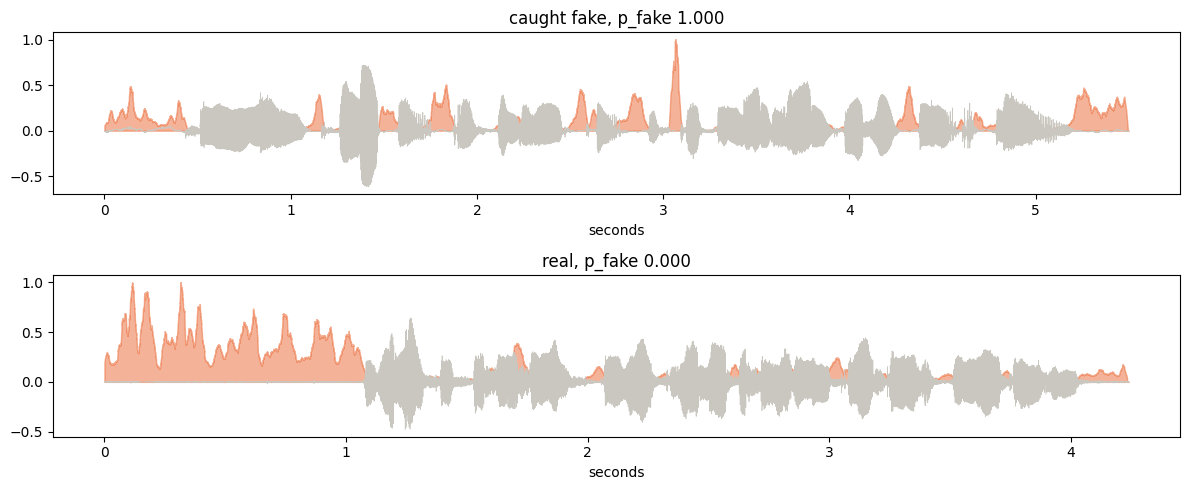

In [43]:
from src.model import load_model
from src.explain import saliency

final_model = load_model(checkpoint(FINAL_RUNS[0]), config(FINAL_RUNS[0]), DEVICE)
picks = {"caught fake": final[(final.split == "test_indomain") & (final.label == "fake")
                              & (final.predicted == "fake")].iloc[0],
         "real": final[(final.split == "test_indomain") & (final.label == "real")].iloc[0]}
fig, axes = plt.subplots(len(picks), 1, figsize=(12, 5))
for ax, (name, row) in zip(axes, picks.items()):
    wave, sr = sf.read(DATA / manifest.set_index("clip_id").path[row.clip_id], dtype="float32")
    sal = saliency(final_model, wave, DEVICE)
    t = np.arange(len(wave)) / sr
    ax.plot(t, wave, color="#c9c7bf", linewidth=0.5)
    ax.fill_between(np.linspace(0, t[-1], len(sal)), 0, sal / sal.max(), color="#eb6834", alpha=0.5)
    ax.set(title=f"{name}, p_fake {row.p_fake:.3f}", xlabel="seconds")
plt.tight_layout()
plt.show()

### 7.10 Sample outputs

One real and one fake clip from each test split, chosen at random (seed 42), with successes and failures. The
confidence is the model's probability for the label it predicts.

In [44]:
samples = final[final.split != "valid"].groupby(["split", "label"]).sample(1, random_state=SEED)
samples["confidence"] = np.where(samples.predicted == "fake", samples.p_fake, 1 - samples.p_fake).round(3)
samples["correct"] = np.where(samples.predicted == samples.label, "yes", "no")
samples[["clip_id", "split", "language", "generator", "label", "predicted", "p_fake", "confidence", "correct"]]

,clip_id,split,language,generator,label,predicted,p_fake,confidence,correct
8000,asvspoof_LA_E_1939320,test_asvspoof,en,A18,fake,fake,0.99997,1.000,yes
8539,asvspoof_LA_E_7146859,test_asvspoof,en,none,real,real,0.00083,0.999,yes
4003,indicsynth_hi_freevc24____f____src_89____tgt_3...,test_indomain,hi,freevc24,fake,fake,0.99996,1.000,yes
4908,kathbath_te_844424932679206-832-f,test_indomain,te,none,real,real,0.00007,1.000,yes
7395,itw_23585,test_itw,en,unknown_tts,fake,fake,0.99997,1.000,yes
7682,itw_3491,test_itw,en,none,real,real,0.00009,1.000,yes
6250,phone_indicsynth_ta_xtts_v2____499-m-688,test_phone,ta,xtts_v2,fake,fake,0.99997,1.000,yes
6754,phone_kathbath_ta_844424933326299-340-m,test_phone,ta,none,real,real,0.00007,1.000,yes
5017,hi_0301_indic-parler-tts,test_unseen_gen,hi,indic-parler-tts,fake,real,0.00064,0.999,no
5819,kathbath_te_844424931033644-831-m,test_unseen_gen,te,none,real,real,0.00009,1.000,yes


In [45]:
paths = manifest.set_index("clip_id").path
for row in samples.itertuples():
    print(f"{row.split} | true: {row.label} | predicted: {row.predicted} ({row.confidence})")
    display(Audio(DATA / paths[row.clip_id]))

test_asvspoof | true: fake | predicted: fake (1.0)


test_asvspoof | true: real | predicted: real (0.999)


test_indomain | true: fake | predicted: fake (1.0)


test_indomain | true: real | predicted: real (1.0)


test_itw | true: fake | predicted: fake (1.0)


test_itw | true: real | predicted: real (1.0)


test_phone | true: fake | predicted: fake (1.0)


test_phone | true: real | predicted: real (1.0)


test_unseen_gen | true: fake | predicted: real (0.999)


test_unseen_gen | true: real | predicted: real (1.0)


## 8. Training Artifacts

In [46]:
rows = []
for run_id in runs.run_id:
    folder = RESULTS / run_id
    files = sorted(p.name for p in folder.glob("*")) if folder.exists() else []
    ckpt = checkpoint(run_id)
    rows.append({"run": run_id, "owner": runs.set_index("run_id").owner[run_id], "files in results/": ", ".join(files),
                 "checkpoint": f"{ckpt.stat().st_size / 1e9:.2f} GB" if ckpt.exists() else "not attached",
                 "Kaggle notebook": runs.set_index("run_id").kaggle_notebook[run_id]})
pd.DataFrame(rows)

,run,owner,files in results/,checkpoint,Kaggle notebook
0,A-01,Amit,"config.yaml, epoch_log.csv, predictions.csv, r...",not attached,https://www.kaggle.com/code/amit1506/milestone...
1,A-02,Amit,"config.yaml, epoch_log.csv, predictions.csv, r...",not attached,https://www.kaggle.com/code/amit1506/milestone...
2,C-hi,Tarika,"config.yaml, epoch_log.csv, predictions.csv, r...",not attached,https://www.kaggle.com/code/tarikasubhashhedao...
3,C-ta,Tarika,"config.yaml, epoch_log.csv, predictions.csv, r...",not attached,https://www.kaggle.com/code/tarikasubhashhedao...
4,C-te,Tarika,"config.yaml, epoch_log.csv, predictions.csv, r...",not attached,https://www.kaggle.com/code/tarikasubhashhedao...
5,D-01,Tarika,"config.yaml, epoch_log.csv, predictions.csv, r...",not attached,https://www.kaggle.com/code/tarikasubhashhedao...
6,F-01,Himanshu,"config.yaml, epoch_eval.csv, epoch_log.csv, pr...",1.26 GB,https://www.kaggle.com/code/tarikasubhashhedao...
7,F-02,Himanshu,"config.yaml, epoch_log.csv, predictions.csv, r...",not attached,https://www.kaggle.com/code/amit1506/milestone...
8,F-03,Himanshu,"config.yaml, epoch_log.csv, predictions.csv, r...",not attached,https://www.kaggle.com/code/viknegi/m4-trainin...
9,T-01,Tarika,"config.yaml, epoch_log.csv, run.json, train_lo...",not attached,https://www.kaggle.com/code/tarikasubhashhedao...


| Artifact | Where |
| --- | --- |
| Training, evaluation and augmentation code | `src/` |
| One config per run | `configs/` and `results/<run>/config.yaml` |
| Training logs (per step and per epoch) | `results/<run>/train_log.csv`, `epoch_log.csv` |
| Predictions and metrics | `results/<run>/predictions.csv`, `results.json` |
| One summary per run | `results/<run>/run.json` (combined by `python -m src.collect_runs`) |
| Model weights (`best.pt`, one per run) | The output of the Kaggle notebook that trained it (linked in `run.json`) |
| Per-run Kaggle notebook | `notebooks/Milestone-4/02_training.ipynb` |

## 9. Summary and Key Findings

_Filled in after the final runs._

**Milestone-3 limitations and what happened to them:**

| Milestone-3 limitation | What Milestone 4 did | Evidence | Result |
| --- | --- | --- | --- |
| One epoch on 1,492 clips | ~15k training clips, up to 10 epochs, early stopping | 4.6, 6.1 | |
| Not exactly repeatable | 3 seeds of the final model, mean ± std | 6.4 | |
| Scores bunched (0.20–0.65) | Longer training | 6.1, 7.8 histograms | |
| `valid` threshold fails on ASVspoof eval | Per-source score analysis | 7.8 | |
| IndicF5 rarely caught (26.7%) | Augmentation, per-generator tracking | 7.4 | |
| No augmentation | Noise, gain, speed, pitch, reverberation, RawBoost, codec | 4.4, 4.5 | |
| Only 4 s per clip | Several windows per clip | 7.6 | |
| ASVspoof train/dev missed some attacks | Every attack A01–A06 in training | 7.5 | |
| Baselines not trained | LFCC-LCNN and AASIST-L on the same splits | 3, 5 | |
| No cross-language or phone-channel test | Both added | 7.1, 7.7 | |
| No explanation view | Gradient saliency | 7.9 | |
| Possible click shortcut in real Kathbath clips | Checked; random time offset in augmentation | 2.1 | |

**What worked well:**

**What didn't perform as expected:**

**Bottlenecks:**

**Plans for improvement (Milestone 5):**